**Student Name:** Andrew Ocasio Serrano
**Target Company:** CrowdStrike (Falcon Complete)
**Problem:** Choosing an alert threshold and analyst staffing level for SOC alert triage
**Objectives:** Maximize detection rate vs. maximize daily labor cost savings

# CrowdStrike Falcon Complete: SOC Alert Triage Optimization
## Part 1: Optimization Engine (Unit 11)

## Overview
This notebook finds the best tradeoffs between detection coverage, meaning catching the real attacks and daily SOC Analyst labor cost, using alert threshold and analysts for each shift as the decision variables. Finding the best balance for finding real alerts and SOC Analysts availability.

## 1. Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv('data/soc_alert_data.csv')

# Display first rows
print("Data loaded successfully!")
print(f"Shape: {df.shape}")
print("\nFirst 5 rows:")
print(df.head())

Data loaded successfully!
Shape: (100, 8)

First 5 rows:
   alert_threshold  analysts_per_shift  alerts_per_day  detection_rate  \
0               10                   3            5038           0.154   
1               10                   4            5151           0.184   
2               10                   5            5284           0.208   
3               10                   6            4944           0.247   
4               10                   7            5023           0.278   

   false_positive_rate  avg_triage_minutes  avg_critical_response_minutes  \
0                0.992                10.0                          180.0   
1                0.992                10.0                          180.0   
2                0.992                10.0                          180.0   
3                0.992                10.0                          180.0   
4                0.992                10.0                          180.0   

   daily_labor_cost  
0            

## 2. Data Validation and Exploration

In [2]:
df['cost_savings'] = df['daily_labor_cost'].max() - df['daily_labor_cost']

# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Basic statistics
print("\nBasic statistics:")
print(df.describe())

# Check ranges of the decision variables
print(f"\nAlert threshold range: {df['alert_threshold'].min()} to {df['alert_threshold'].max()}")
print(f"Analysts per shift range: {df['analysts_per_shift'].min()} to {df['analysts_per_shift'].max()}")
print(f"Total combinations: {len(df)}")

print(f"\nDetection rate range: {df['detection_rate'].min():.3f} to {df['detection_rate'].max():.3f}")
print(f"Cost savings range: ${df['cost_savings'].min():,.0f} to ${df['cost_savings'].max():,.0f}")

# Verify they create a tradeoff
correlation = df['detection_rate'].corr(df['cost_savings'])
print(f"\nCorrelation between objectives: {correlation:.3f}")
print("(Negative correlation suggests a tradeoff)")

Missing values:
alert_threshold                  0
analysts_per_shift               0
alerts_per_day                   0
detection_rate                   0
false_positive_rate              0
avg_triage_minutes               0
avg_critical_response_minutes    0
daily_labor_cost                 0
cost_savings                     0
dtype: int64

Data types:
alert_threshold                    int64
analysts_per_shift                 int64
alerts_per_day                     int64
detection_rate                   float64
false_positive_rate              float64
avg_triage_minutes               float64
avg_critical_response_minutes    float64
daily_labor_cost                   int64
cost_savings                       int64
dtype: object

Basic statistics:
       alert_threshold  analysts_per_shift  alerts_per_day  detection_rate  \
count       100.000000          100.000000      100.000000      100.000000   
mean         55.000000            7.500000     1288.460000        0.447920   
std    

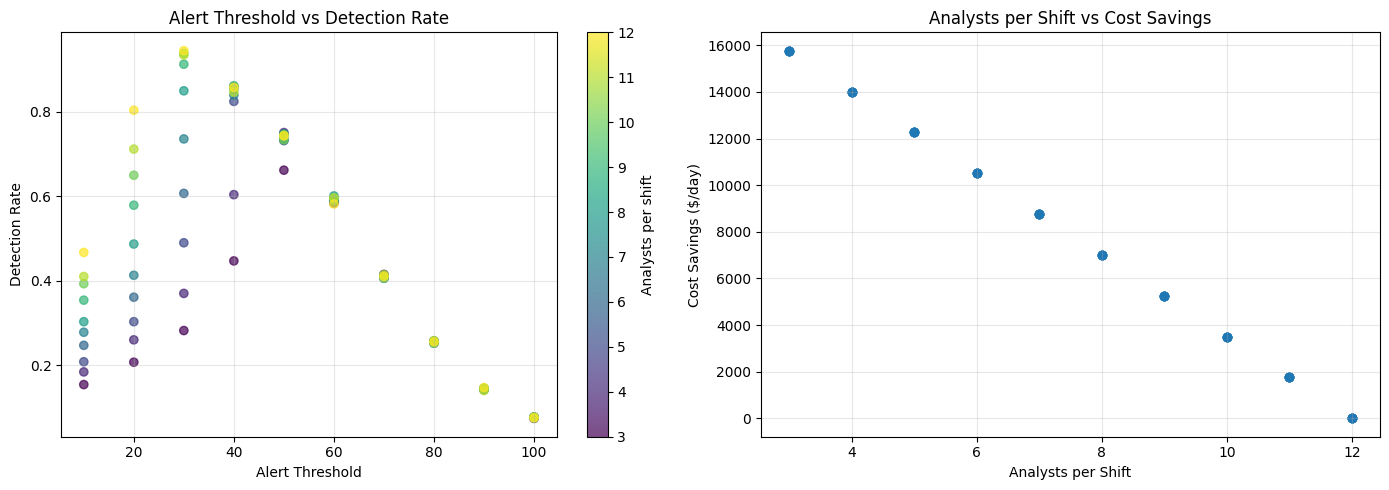

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc = axes[0].scatter(df['alert_threshold'], df['detection_rate'],
                     c=df['analysts_per_shift'], cmap='viridis', alpha=0.7)
fig.colorbar(sc, ax=axes[0], label='Analysts per shift')
axes[0].set_xlabel('Alert Threshold')
axes[0].set_ylabel('Detection Rate')
axes[0].set_title('Alert Threshold vs Detection Rate')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(df['analysts_per_shift'], df['cost_savings'], alpha=0.5)
axes[1].set_xlabel('Analysts per Shift')
axes[1].set_ylabel('Cost Savings ($/day)')
axes[1].set_title('Analysts per Shift vs Cost Savings')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('images/data_exploration.png', dpi=300, bbox_inches='tight')
plt.show()

### Data Validation Findings

- There are no missing values present since all of the 100 rows contain complete information (10 thresholds of alert x 10 levels of manpower).
- The detection rate varies between 7% and 94.5% while the cost savings vary between $0 and $15,768 of daily expenses.
- A correlation coefficient of -0.24 indicates a weak correlation between detection rate and cost savings; alert threshold exerts more influence on detection than staffing does.
- The charts show that the peak detection is detected at the middle thresholds (from 30 to 50), and the detection is reduced at high thresholds as the cost of manpower is reduced gradually with the increase of manpower.
- The data coincides with the proposal: more professionals mean higher expenses and the threshold determines the amount of suspected attacks.

## 3. Pareto Frontier Calculation

In [4]:
def is_pareto_optimal(idx, df, obj1_col, obj2_col):
    """
    Check if a given row represents a Pareto optimal solution.
    
    A point is Pareto optimal if no other point dominates it.
    Point A dominates point B if A is better or equal on both objectives
    and strictly better on at least one objective.
    
    Parameters:
    -----------
    idx : int
        Index of the row to check
    df : DataFrame
        The full dataset
    obj1_col : str
        Column name for objective 1
    obj2_col : str
        Column name for objective 2
    
    Returns:
    --------
    bool : True if Pareto optimal, False if dominated
    """
    current_obj1 = df.loc[idx, obj1_col]
    current_obj2 = df.loc[idx, obj2_col]
    
    # Check if any other point dominates this one
    for other_idx in df.index:
        if other_idx == idx:
            continue
        
        other_obj1 = df.loc[other_idx, obj1_col]
        other_obj2 = df.loc[other_idx, obj2_col]
        
        if (other_obj1 >= current_obj1 and 
            other_obj2 >= current_obj2 and
            (other_obj1 > current_obj1 or other_obj2 > current_obj2)):
            return False  # This point is dominated
    
    return True  # No point dominates this one

In [5]:
OBJECTIVE_1 = 'detection_rate'
OBJECTIVE_2 = 'cost_savings'

print("Calculating Pareto frontier...")
print("This may take a moment for large datasets...")

# Apply Pareto check to all rows
df['is_pareto_optimal'] = df.index.map(
    lambda idx: is_pareto_optimal(idx, df, OBJECTIVE_1, OBJECTIVE_2)
)

# Separate into frontier and dominated points
pareto_df = df[df['is_pareto_optimal']].copy()
dominated_df = df[~df['is_pareto_optimal']].copy()

print("\n=== PARETO FRONTIER RESULTS ===")
print(f"Total solutions analyzed: {len(df)}")
print(f"Pareto optimal solutions: {len(pareto_df)}")
print(f"Dominated solutions: {len(dominated_df)}")
print(f"Efficiency rate: {100 * len(pareto_df) / len(df):.1f}% of solutions are on the frontier")

Calculating Pareto frontier...
This may take a moment for large datasets...

=== PARETO FRONTIER RESULTS ===
Total solutions analyzed: 100
Pareto optimal solutions: 7
Dominated solutions: 93
Efficiency rate: 7.0% of solutions are on the frontier


### Interpretation

- Of the 100 possible combinations, only 7 (7%) are optimal according to Pareto efficiency. The other 93 combinations are dominated as some other combination detects as well or better (but at a lower cost).
- I assumed a small number for the reason that personnel limitations don't seem as much to be a factor in detection performance as threshold selection.
- The frontier is so small mainly because of importance of the threshold. Most combinations are ineffective - a wrong threshold can affect the detection quality no matter how many people are recruited.
- The point is that the more personnel that's needed, the more you'll have to pay for to be able to move up from the cheap detection world to the great detection world.

## 4. Inefficient Solutions Analysis

In [6]:
if len(dominated_df) > 0:
    print("=== EXAMPLES OF DOMINATED (INEFFICIENT) SOLUTIONS ===\n")
    
    # Sample a few dominated points
    sample_size = min(3, len(dominated_df))
    sample_dominated = dominated_df.sample(sample_size, random_state=42)
    
    for idx, row in sample_dominated.iterrows():
        print(f"INEFFICIENT SOLUTION:")
        print(f"  Decision Variables: {row['alert_threshold']}, {row['analysts_per_shift']}")
        print(f"  Objectives: {OBJECTIVE_1}={row[OBJECTIVE_1]:.3f}, {OBJECTIVE_2}={row[OBJECTIVE_2]:,.0f}")
        
        for p_idx, p_row in pareto_df.iterrows():
            if (p_row[OBJECTIVE_1] >= row[OBJECTIVE_1] and 
                p_row[OBJECTIVE_2] >= row[OBJECTIVE_2] and
                (p_row[OBJECTIVE_1] > row[OBJECTIVE_1] or 
                 p_row[OBJECTIVE_2] > row[OBJECTIVE_2])):
                
                print(f"\n  BETTER ALTERNATIVE (Pareto Optimal):")
                print(f"  Decision Variables: {p_row['alert_threshold']}, {p_row['analysts_per_shift']}")
                print(f"  Objectives: {OBJECTIVE_1}={p_row[OBJECTIVE_1]:.3f}, {OBJECTIVE_2}={p_row[OBJECTIVE_2]:,.0f}")
                print(f"  Improvement: +{p_row[OBJECTIVE_1] - row[OBJECTIVE_1]:.3f} on {OBJECTIVE_1}, " +
                      f"+{p_row[OBJECTIVE_2] - row[OBJECTIVE_2]:,.0f} on {OBJECTIVE_2}\n")
                print("-" * 60)
                break
else:
    print("Note: All solutions in your dataset are Pareto optimal.")
    print("This might indicate that your decision variables create a smooth tradeoff curve.")

=== EXAMPLES OF DOMINATED (INEFFICIENT) SOLUTIONS ===

INEFFICIENT SOLUTION:
  Decision Variables: 50, 10
  Objectives: detection_rate=0.734, cost_savings=3,504

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: 30, 9
  Objectives: detection_rate=0.913, cost_savings=5,256
  Improvement: +0.179 on detection_rate, +1,752 on cost_savings

------------------------------------------------------------
INEFFICIENT SOLUTION:
  Decision Variables: 30, 5
  Objectives: detection_rate=0.490, cost_savings=12,264

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: 40, 5
  Objectives: detection_rate=0.825, cost_savings=12,264
  Improvement: +0.335 on detection_rate, +0 on cost_savings

------------------------------------------------------------
INEFFICIENT SOLUTION:
  Decision Variables: 70, 5
  Objectives: detection_rate=0.411, cost_savings=12,264

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: 40, 5
  Objectives: detection_rate=0.825, cost_savings=12,264
  Improv

In [7]:
# Compare best dominated point to worst Pareto point
if len(dominated_df) > 0:
    best_dominated = dominated_df.loc[
        (dominated_df[OBJECTIVE_1] + dominated_df[OBJECTIVE_2]).idxmax()
    ]
    worst_pareto = pareto_df.loc[
        (pareto_df[OBJECTIVE_1] + pareto_df[OBJECTIVE_2]).idxmin()
    ]
    
    print("\n=== EFFICIENCY GAP ===")
    print(f"\nBest Dominated: {OBJECTIVE_1}={best_dominated[OBJECTIVE_1]:.3f}, " +
          f"{OBJECTIVE_2}={best_dominated[OBJECTIVE_2]:,.0f}")
    print(f"Worst Pareto: {OBJECTIVE_1}={worst_pareto[OBJECTIVE_1]:.3f}, " +
          f"{OBJECTIVE_2}={worst_pareto[OBJECTIVE_2]:,.0f}")


=== EFFICIENCY GAP ===

Best Dominated: detection_rate=0.585, cost_savings=15,768
Worst Pareto: detection_rate=0.945, cost_savings=0


### Findings

- For each dominated case there exists a Pareto alternative that is better or equal on both objectives and better on at least one of them. So selecting the dominated choice is an inefficient way to spend money or not to take advantage of an attack opportunity.
- The highest savings are obtained when the best dominated point is used (threshold 60 and 3 analysts) but they record only a 58.5% detection rate. The worst (30 and 12 analysts) Pareto efficiency point in terms of detection rate is a 94.5% rate with no savings. None of them is able to achieve both goals.
- This indicates that there are conflicting goals and that they cannot be optimised independently but must be compared as a trade-off, taking different degrees of aversion to risk into account.

## 5. Strategic Analysis

In [8]:
pareto_df['obj1_scaled'] = (pareto_df[OBJECTIVE_1] - pareto_df[OBJECTIVE_1].min()) / (pareto_df[OBJECTIVE_1].max() - pareto_df[OBJECTIVE_1].min())
pareto_df['obj2_scaled'] = (pareto_df[OBJECTIVE_2] - pareto_df[OBJECTIVE_2].min()) / (pareto_df[OBJECTIVE_2].max() - pareto_df[OBJECTIVE_2].min())

print("=== KEY STRATEGIC POINTS ON THE PARETO FRONTIER ===\n")

# Strategy 1: Balanced (Maximize total value)
pareto_df['total_objective'] = pareto_df['obj1_scaled'] + pareto_df['obj2_scaled']
balanced_idx = pareto_df['total_objective'].idxmax()

print("1. BALANCED STRATEGY (Maximize combined objectives)")
print(f"   Decision Variables: {pareto_df.loc[balanced_idx, 'alert_threshold']}, {pareto_df.loc[balanced_idx, 'analysts_per_shift']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[balanced_idx, OBJECTIVE_1]:.3f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[balanced_idx, OBJECTIVE_2]:,.0f}")
print(f"   Total (scaled): {pareto_df.loc[balanced_idx, 'total_objective']:.3f}\n")

# Strategy 2: Equity (Minimize gap between objectives)
pareto_df['objective_gap'] = abs(pareto_df['obj1_scaled'] - pareto_df['obj2_scaled'])
equity_idx = pareto_df['objective_gap'].idxmin()

print("2. EQUITY STRATEGY (Most equal outcomes)")
print(f"   Decision Variables: {pareto_df.loc[equity_idx, 'alert_threshold']}, {pareto_df.loc[equity_idx, 'analysts_per_shift']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[equity_idx, OBJECTIVE_1]:.3f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[equity_idx, OBJECTIVE_2]:,.0f}")
print(f"   Gap (scaled): {pareto_df.loc[equity_idx, 'objective_gap']:.3f}\n")

# Strategy 3: Objective 1 Priority (Maximize first objective)
obj1_priority_idx = pareto_df[OBJECTIVE_1].idxmax()

print("3. OBJECTIVE 1 PRIORITY (Maximize first stakeholder)")
print(f"   Decision Variables: {pareto_df.loc[obj1_priority_idx, 'alert_threshold']}, {pareto_df.loc[obj1_priority_idx, 'analysts_per_shift']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[obj1_priority_idx, OBJECTIVE_1]:.3f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[obj1_priority_idx, OBJECTIVE_2]:,.0f}\n")

# Strategy 4: Objective 2 Priority (Maximize second objective)
obj2_priority_idx = pareto_df[OBJECTIVE_2].idxmax()

print("4. OBJECTIVE 2 PRIORITY (Maximize second stakeholder)")
print(f"   Decision Variables: {pareto_df.loc[obj2_priority_idx, 'alert_threshold']}, {pareto_df.loc[obj2_priority_idx, 'analysts_per_shift']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[obj2_priority_idx, OBJECTIVE_1]:.3f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[obj2_priority_idx, OBJECTIVE_2]:,.0f}\n")

# Strategy 5: Custom weighted (e.g., 60/40 split)
pareto_df['weighted_objective'] = (0.6 * pareto_df['obj1_scaled'] + 
                                   0.4 * pareto_df['obj2_scaled'])
weighted_idx = pareto_df['weighted_objective'].idxmax()

print("5. WEIGHTED STRATEGY (60% objective 1, 40% objective 2)")
print(f"   Decision Variables: {pareto_df.loc[weighted_idx, 'alert_threshold']}, {pareto_df.loc[weighted_idx, 'analysts_per_shift']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[weighted_idx, OBJECTIVE_1]:.3f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[weighted_idx, OBJECTIVE_2]:,.0f}")

=== KEY STRATEGIC POINTS ON THE PARETO FRONTIER ===

1. BALANCED STRATEGY (Maximize combined objectives)
   Decision Variables: 40, 6
   detection_rate: 0.860
   cost_savings: 10,512
   Total (scaled): 1.366

2. EQUITY STRATEGY (Most equal outcomes)
   Decision Variables: 40, 6
   detection_rate: 0.860
   cost_savings: 10,512
   Gap (scaled): 0.033

3. OBJECTIVE 1 PRIORITY (Maximize first stakeholder)
   Decision Variables: 30, 12
   detection_rate: 0.945
   cost_savings: 0

4. OBJECTIVE 2 PRIORITY (Maximize second stakeholder)
   Decision Variables: 50, 3
   detection_rate: 0.662
   cost_savings: 15,768

5. WEIGHTED STRATEGY (60% objective 1, 40% objective 2)
   Decision Variables: 40, 6
   detection_rate: 0.860
   cost_savings: 10,512


In [9]:
# Build comparison dataframe
idxs = [obj1_priority_idx, weighted_idx, balanced_idx, equity_idx, obj2_priority_idx]

strategies = {
    'Strategy': [
        'Objective 1 Priority',
        'Weighted (60/40)',
        'Balanced',
        'Equity',
        'Objective 2 Priority'
    ],
    'Alert Threshold': [pareto_df.loc[i, 'alert_threshold'] for i in idxs],
    'Analysts per Shift': [pareto_df.loc[i, 'analysts_per_shift'] for i in idxs],
    OBJECTIVE_1: [f"{pareto_df.loc[i, OBJECTIVE_1]:.3f}" for i in idxs],
    OBJECTIVE_2: [f"{pareto_df.loc[i, OBJECTIVE_2]:,.0f}" for i in idxs]
}

comparison_df = pd.DataFrame(strategies)

print("\n" + "="*80)
print("STRATEGIC OPTIONS COMPARISON")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)


STRATEGIC OPTIONS COMPARISON
            Strategy  Alert Threshold  Analysts per Shift detection_rate cost_savings
Objective 1 Priority               30                  12          0.945            0
    Weighted (60/40)               40                   6          0.860       10,512
            Balanced               40                   6          0.860       10,512
              Equity               40                   6          0.860       10,512
Objective 2 Priority               50                   3          0.662       15,768


### Strategic Findings

- The detection priority option (threshold of 30, 12 analysts) captures 94.5% of attacks but saves no money. The cost priority option (threshold of 50, 3 analysts) provides the maximum savings ($15,768 per day) but only detects 66.2% of attacks.
- The balanced, equity, and weighted 60/40 priorities all choose the same point (threshold of 40, 6 analysts), with 86% detection and $10,512 in savings.
- It is advisable to select the balanced option (threshold of 40, 6 analysts). It offers 86% detection without having to employ 12 analysts (as with the detection priority).

## 6. Visualization

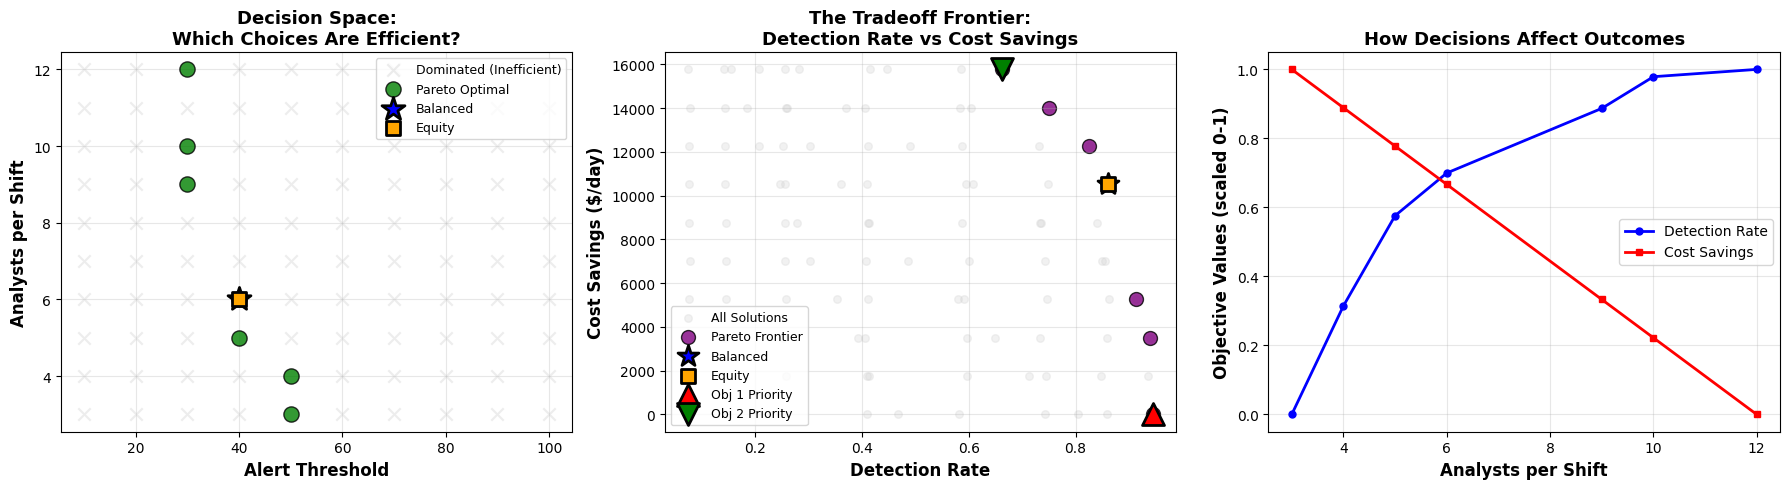


 Visualization saved as 'images/pareto_frontier_analysis.png'


In [11]:
# Create figure with three subplots
fig = plt.figure(figsize=(18, 5))

# PANEL 1: Decision Space (show which variable combinations are efficient)
ax1 = fig.add_subplot(131)

# Plot dominated points
if len(dominated_df) > 0:
    ax1.scatter(dominated_df['alert_threshold'], dominated_df['analysts_per_shift'],
               s=80, c='lightgray', alpha=0.4, marker='x', 
               label='Dominated (Inefficient)', zorder=1)

# Plot Pareto optimal points
ax1.scatter(pareto_df['alert_threshold'], pareto_df['analysts_per_shift'],
           s=120, c='green', alpha=0.8, marker='o', 
           edgecolors='black', linewidth=1,
           label='Pareto Optimal', zorder=2)

# Highlight key strategies
ax1.scatter(pareto_df.loc[balanced_idx, 'alert_threshold'], 
           pareto_df.loc[balanced_idx, 'analysts_per_shift'],
           s=300, c='blue', marker='*', 
           edgecolors='black', linewidth=2, 
           label='Balanced', zorder=3)

ax1.scatter(pareto_df.loc[equity_idx, 'alert_threshold'],
           pareto_df.loc[equity_idx, 'analysts_per_shift'],
           s=100, c='orange', marker='s',
           edgecolors='black', linewidth=2,
           label='Equity', zorder=4)

ax1.set_xlabel('Alert Threshold', fontsize=12, fontweight='bold')
ax1.set_ylabel('Analysts per Shift', fontsize=12, fontweight='bold')
ax1.set_title('Decision Space:\nWhich Choices Are Efficient?', 
              fontsize=13, fontweight='bold')
ax1.legend(fontsize=9, loc='best')
ax1.grid(True, alpha=0.3)

# PANEL 2: Objective Space (the Pareto frontier)
ax2 = fig.add_subplot(132)

# Plot all points
ax2.scatter(df[OBJECTIVE_1], df[OBJECTIVE_2],
           s=30, c='lightgray', alpha=0.3, 
           label='All Solutions')

# Plot Pareto frontier
ax2.scatter(pareto_df[OBJECTIVE_1], pareto_df[OBJECTIVE_2],
           s=100, c='purple', alpha=0.8, 
           edgecolors='black', linewidth=1,
           label='Pareto Frontier')

# Highlight strategies
strategies_to_plot = [
    (balanced_idx, 'blue', '*', 'Balanced', 250, 5),
    (equity_idx, 'orange', 's', 'Equity', 100, 6),
    (obj1_priority_idx, 'red', '^', 'Obj 1 Priority', 250, 5),
    (obj2_priority_idx, 'green', 'v', 'Obj 2 Priority', 250, 5)
]

for idx, color, marker, label, size, z in strategies_to_plot:
    ax2.scatter(pareto_df.loc[idx, OBJECTIVE_1],
               pareto_df.loc[idx, OBJECTIVE_2],
               s=size, c=color, marker=marker, 
               edgecolors='black', linewidth=2, 
               label=label, zorder=z)

ax2.set_xlabel('Detection Rate', fontsize=12, fontweight='bold')
ax2.set_ylabel('Cost Savings ($/day)', fontsize=12, fontweight='bold')
ax2.set_title('The Tradeoff Frontier:\nDetection Rate vs Cost Savings', 
              fontsize=13, fontweight='bold')
ax2.legend(fontsize=9, loc='lower left')
ax2.grid(True, alpha=0.3)

# PANEL 3: Tradeoff Curve (both objectives vs one decision variable)
ax3 = fig.add_subplot(133)

pareto_sorted = pareto_df.sort_values('analysts_per_shift')

ax3.plot(pareto_sorted['analysts_per_shift'], pareto_sorted['obj1_scaled'],
        'b-o', linewidth=2, markersize=5, label='Detection Rate')
ax3.plot(pareto_sorted['analysts_per_shift'], pareto_sorted['obj2_scaled'],
        'r-s', linewidth=2, markersize=5, label='Cost Savings')

ax3.set_xlabel('Analysts per Shift', fontsize=12, fontweight='bold')
ax3.set_ylabel('Objective Values (scaled 0-1)', fontsize=12, fontweight='bold')
ax3.set_title('How Decisions Affect Outcomes', 
              fontsize=13, fontweight='bold')
ax3.legend(fontsize=10, loc='best')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('images/pareto_frontier_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n Visualization saved as 'images/pareto_frontier_analysis.png'")

### What the Panels Show
- **Decision Space (left):** Only 7 combinations of threshold and staffing are effective out of the 100 combinations explored. They are at threshold values of 30-50. Any combination above 50 is ineffective.
- **Tradeoff Frontier (middle):** Purple points represent the best trade-offs known. Whenever the detection is raised, so is the loss of savings, and the Balanced point (40, 6) is located between these two dimensions.
- **Decisions vs Outcomes (right):** The more analysts you add, the more you will detect, but the savings will also decrease, and the gains are small beyond 6 analysts.
- **Conclusion for executives:** Only 7 combinations are viable and all other combinations result in useless spending of money or missing attacks. The best option is to start from the balanced state (threshold value of 40 and 6 analysts) and proceed either toward increasing or decreasing the number of analysts depending on the level of acceptable risk.

## 7. Summary and Insights

### What I Found

I used 100 different combinations of number of analysts per shift and alert threshold, and only 7 (7%) combinations were Pareto optimal. The detection rate at the boundary of the results may range from 66.2% to 94.5% and the cost savings can be as low as $0 and as high as $15,768. The three solutions that are the best include detection-first guidance (threshold 30, 12 analysts), cost-first guidance (threshold 50, 3 analysts), and an intermediate approach combining both aspects (threshold 40, 6 analysts), which is also in line with equity and 60/40 preference.

### Business Implications

The analysis shows that there is a trade off between detection and cost; as the number of analysts increases, detection becomes better, but savings go down, and the improvement after the sixth analyst is not significant. Companies should steer clear of alert thresholds above 50 and thresholds in the range of 10 to 20, because none of those combinations are efficient. The 7 ideal points signify three ways to tackle the challenge of detection: emphasis on detection (30, 12), cost (50, 3), and compromise (40, 6). Risk tolerance, operating budget, and mean financial burden of undetected events are some of the key factors that can help the company make an informed decision.

### Limitations

Data used are synthetic and only 100 combinations are used. The actual strength of SOC may not be the same as this model, however, as it only includes 2 decision variables and 2 objectives. Besides, it presumes that an analyst offers the same service as well as expenses an hourly fee. It also doesn’t take any constraints into account; for example, the average critical response time of the balanced variant is 17 minutes, although the target response time is set to 15 minutes. Future works should benefit from historical SOC data, consider varying level of analysts experience, and also place SLA constraints on the optimization model (e.g. critical response time).